# 14 — X-IIoTID Core19 | Detection Scores, Model Selection & Laptop Resource Benchmark

**Project:** J26-CS-336 · Network Flow V2 · Full-training evaluation for IIoT edge readiness

## How to use this notebook

**Run from top to bottom.** It first **proves the detection calculations** using the five saved validation confusion matrices, shows the **detection-performance graphs first**, and then uses your existing laptop resource benchmark (or optionally reruns it) to compare storage, memory, CPU, single-flow latency and throughput. Finally, it creates a **research-demo shortlist chart and evidence table**.

**Your setup:** `D:\J26-CS-336-Network-Flow-V2\network_flow_v2` (not the old `-Git` path). All models were reported as trained using the **574,585-record X-IIoTID training partition** and assessed on the **123,125-record frozen validation partition**. These reported counts are checked, but the notebook does not itself retrain the models.

**What it does not do:** No training, no synthetic-data generation, **no held-out test partition access**, no Raspberry Pi measurement, no live packet collection or gateway feature extraction. The measured latency includes the **saved preprocessing + classifier pipeline**, but excludes the upstream `clean_features` function used to prepare validation flows.

**For an easy demo:** If the Notebook 14 resource benchmark CSV already exists, the notebook **reuses those measured results** instead of rerunning expensive CPU/RAM tests. Change `REUSE_SAVED_BENCHMARK = False` in the resource benchmark cell to measure your laptop again. Reusing data does **not** make it a new measurement.

**Required packages:** `pandas`, `numpy`, `matplotlib`, `psutil`, `joblib`, `scikit-learn`, `lightgbm` with the existing `.venv` kernel. Install `psutil` manually if missing: `%pip install psutil`.


In [1]:
from pathlib import Path
import sys, os, json, importlib.util
import pandas as pd
from IPython.display import display

ROOT = Path(r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2")
assert ROOT.is_dir(), f"Research folder missing: {ROOT}"
assert (ROOT / "src" / "x_iiotid_model_runner.py").is_file(), "Missing shared model runner"

AUDIT_DIR = ROOT / "reports" / "audits"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models" / "x_iiotid"
VALIDATION = ROOT / "data" / "splits" / "x_iiotid_core19_validation_v1.csv.gz"
for folder in [AUDIT_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
assert VALIDATION.is_file(), f"Frozen validation split missing: {VALIDATION}"

MODELS = ["decision_tree", "random_forest", "extra_trees", "lightgbm", "adaboost"]
DISPLAY_NAMES = {"decision_tree":"Decision Tree", "random_forest":"Random Forest",
                 "extra_trees":"Extra Trees", "lightgbm":"LightGBM", "adaboost":"AdaBoost"}

missing_packages = [name for name in ["psutil", "joblib", "sklearn", "numpy", "pandas", "matplotlib", "lightgbm"]
                    if importlib.util.find_spec(name) is None]
if missing_packages:
    raise ImportError(f"Install these packages in the active notebook kernel, then rerun: {missing_packages}. Example: %pip install psutil")

print("Active Python:", sys.executable)
print("Workspace:", ROOT)
print("Host:", sys.platform, "| Logical CPUs:", os.cpu_count())
print("Input partition: VALIDATION only (held-out test is sealed)")

Active Python: d:\J26-CS-336-Network-Flow-V2\network_flow_v2\.venv\Scripts\python.exe
Workspace: D:\J26-CS-336-Network-Flow-V2\network_flow_v2
Host: win32 | Logical CPUs: 8
Input partition: VALIDATION only (held-out test is sealed)


## A. Verify the five full-trained reports & model files

The report row count verifies what the evaluation **recorded**. The saved `.joblib` format does **not** embed an independently verifiable training-row count, so we also check that each model artifact exists and whether its file modification time is consistent with the report. Matching times are **supporting evidence, not cryptographic provenance**.

In [2]:
rows = []
manifest_hashes = set()
for model in MODELS:
    model_file = MODEL_DIR / f"{model}_core19_v1.joblib"
    metric_file = AUDIT_DIR / f"x_iiotid_{model}_validation_v1.csv"
    if not model_file.is_file():
        raise FileNotFoundError(f"Missing trained pipeline: {model_file}")
    if not metric_file.is_file():
        raise FileNotFoundError(f"Missing validation report: {metric_file}")
    rec = pd.read_csv(metric_file).iloc[0]
    if int(rec["train_rows_used"]) != 574_585 or int(rec["validation_rows"]) != 123_125:
        raise AssertionError(f"{model}: report does not show full training + expected validation rows")
    if str(rec["test_evaluated"]).strip().lower() not in ("false", "0"):
        raise AssertionError(f"{model}: report says test was evaluated; stop and investigate")
    manifest_hashes.add(str(rec["frozen_manifest_sha256"]))
    rows.append({
        "model": model,
        "train_rows_reported": int(rec["train_rows_used"]),
        "validation_rows": int(rec["validation_rows"]),
        "f1_attack": float(rec["f1_attack"]),
        "false_positive_rate": float(rec["false_positive_rate"]),
        "model_size_mib": round(model_file.stat().st_size / (1024**2), 3),
        "model_modified_utc": pd.Timestamp(model_file.stat().st_mtime, unit="s", tz="UTC").isoformat(),
        "metrics_modified_utc": pd.Timestamp(metric_file.stat().st_mtime, unit="s", tz="UTC").isoformat(),
        "model_not_older_than_metrics": model_file.stat().st_mtime >= metric_file.stat().st_mtime,
    })
assert len(manifest_hashes) == 1, "Different frozen manifest hashes! Do not compare models yet."
metadata_df = pd.DataFrame(rows)
display(metadata_df)
if not metadata_df["model_not_older_than_metrics"].all():
    print("WARNING: Some saved model files predate their reported metrics; verify which training run created them.")
print("Same frozen manifest hash:", next(iter(manifest_hashes)))

,model,train_rows_reported,validation_rows,f1_attack,false_positive_rate,model_size_mib,model_modified_utc,metrics_modified_utc,model_not_older_than_metrics
0,decision_tree,574585,123125,0.984238,0.010030,0.033,2026-10-22T03:01:04.211244822+00:00,2026-10-22T03:01:01.416071653+00:00,True
1,random_forest,574585,123125,0.987481,0.014412,2.846,2026-10-22T03:02:02.318361282+00:00,2026-10-22T03:02:00.649136543+00:00,True
2,extra_trees,574585,123125,0.928043,0.086438,0.958,2026-10-22T02:51:36.586328745+00:00,2026-10-22T02:51:34.947362185+00:00,True
3,lightgbm,574585,123125,0.989197,0.011422,0.215,2026-10-22T03:03:32.193813086+00:00,2026-10-22T03:03:31.078057051+00:00,True
4,adaboost,574585,123125,0.951713,0.043883,0.029,2026-10-22T03:06:49.294151545+00:00,2026-10-22T03:06:48.278274536+00:00,True


Same frozen manifest hash: 8704e269d96abfe61b61a4608ab4e2f0608952555d6b34730da92ebac31fe2c0


## B. Prove how detection scores are calculated — *from real confusion matrices*

The models are evaluated on **actual saved X-IIoTID validation outcomes**, not made-up scores. Here **Attack is the positive class**:

| Term | Easy meaning | IIoT example |
|---|---|---|
| **TP** (true positive) | Attack correctly detected | Malicious network flow flagged |
| **TN** (true negative) | Normal traffic correctly recognized | Normal sensor communication allowed |
| **FP** (false positive) | Normal traffic wrongly flagged | Harmless CoAP traffic generates an alert |
| **FN** (false negative) | Attack missed | Malicious traffic called normal |

**Formulas:**

- **Accuracy** = `(TP + TN) / (TP + TN + FP + FN)` — all correct predictions.
- **Precision** = `TP / (TP + FP)` — reliability of attack alerts.
- **Recall (attack detection rate)** = `TP / (TP + FN)` — proportion of actual attacks found.
- **F1-score** = `2 × Precision × Recall / (Precision + Recall)` — balance of precision and recall (equivalently `2TP / (2TP + FP + FN)`).
- **False-positive rate (FPR)** = `FP / (FP + TN)` — fraction of normal traffic falsely flagged. **Lower is better**.
- **Specificity** = `TN / (TN + FP)` — fraction of normal traffic correctly allowed.
- **Balanced accuracy** = `(Recall + Specificity) / 2` — average detection of attack and normal classes.

**Important:** The dataset's provisional signature-disjoint split is not confirmed capture/session/device independent. Strong validation results are not yet proof of deployed multi-stage APT detection.

In [3]:
import numpy as np
import pandas as pd

# Calculate every detection score from stored TP/TN/FP/FN counts.
# Never read the held-out test split here.
metric_rows = []
for model_name in MODELS:
    report = AUDIT_DIR / f"x_iiotid_{model_name}_validation_v1.csv"
    r = pd.read_csv(report).iloc[0]
    tp, tn, fp, fn = (int(r[k]) for k in ("tp", "tn", "fp", "fn"))
    total = tp + tn + fp + fn
    assert total == 123_125, f"{model_name}: unexpected validation confusion-matrix total {total}"
    assert int(r["train_rows_used"]) == 574_585
    assert str(r["test_evaluated"]).strip().lower() in ("false", "0")

    accuracy = (tp + tn) / total
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    specificity = tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn)
    fpr = fp / (fp + tn)
    balanced_accuracy = (recall + specificity) / 2

    # Cross-check the recalculation against model reports (rounding allowed).
    for key, value in (("precision_attack", precision), ("recall_attack", recall),
                       ("f1_attack", f1), ("balanced_accuracy", balanced_accuracy),
                       ("false_positive_rate", fpr)):
        assert np.isclose(float(r[key]), value, atol=1e-6), (model_name, key, r[key], value)

    metric_rows.append({
        "model": model_name,
        "train_rows": int(r["train_rows_used"]), "validation_rows": total,
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "accuracy_pct": accuracy * 100, "precision_pct": precision * 100,
        "recall_pct": recall * 100, "f1_pct": f1 * 100,
        "balanced_accuracy_pct": balanced_accuracy * 100,
        "specificity_pct": specificity * 100, "fpr_pct": fpr * 100,
        "manifest_sha256": str(r["frozen_manifest_sha256"]),
    })

performance_df = pd.DataFrame(metric_rows)
assert performance_df["model"].nunique() == 5
assert performance_df["manifest_sha256"].nunique() == 1, "Results are not from same split manifest!"

print("All five validation confusion matrices agree with saved scores and the same frozen split.")
print("Percentages below are CALCULATED from TP/TN/FP/FN:")
display(performance_df[["model", "TP", "TN", "FP", "FN", "accuracy_pct",
                        "precision_pct", "recall_pct", "f1_pct",
                        "balanced_accuracy_pct", "fpr_pct"]].round(3))

metrics_csv = AUDIT_DIR / "x_iiotid_demo_recalculated_detection_metrics_v2.csv"
performance_df.to_csv(metrics_csv, index=False)
print("Saved:", metrics_csv)

All five validation confusion matrices agree with saved scores and the same frozen split.
Percentages below are CALCULATED from TP/TN/FP/FN:


,model,TP,TN,FP,FN,accuracy_pct,precision_pct,recall_pct,f1_pct,balanced_accuracy_pct,fpr_pct
0,decision_tree,58667,62579,634,1245,98.474,98.931,97.922,98.424,98.459,1.003
1,random_forest,59319,62302,911,593,98.778,98.487,99.010,98.748,98.785,1.441
2,extra_trees,56599,57749,5464,3313,92.871,91.196,94.470,92.804,92.913,8.644
3,lightgbm,59338,62491,722,574,98.947,98.798,99.042,98.920,98.950,1.142
4,adaboost,56911,60439,2774,3001,95.310,95.352,94.991,95.171,95.301,4.388


Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_demo_recalculated_detection_metrics_v2.csv


In [4]:
# Live proof for your viva: show the mathematical steps for LightGBM.
lgbm = performance_df.set_index("model").loc["lightgbm"]
tp, tn, fp, fn = (int(lgbm[key]) for key in ("TP", "TN", "FP", "FN"))
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print("LIGHTGBM — HOW THE SCORES WERE CALCULATED")
print("=" * 55)
print(f"TP={tp:,}  TN={tn:,}  FP={fp:,}  FN={fn:,}")
print(f"Accuracy  = ({tp:,} + {tn:,}) / {tp+tn+fp+fn:,} = {lgbm['accuracy_pct']:.3f}%")
print(f"Precision = {tp:,} / ({tp:,} + {fp:,}) = {precision*100:.3f}%")
print(f"Recall    = {tp:,} / ({tp:,} + {fn:,}) = {recall*100:.3f}%")
print(f"F1        = 2 × {precision:.6f} × {recall:.6f} / ({precision:.6f} + {recall:.6f}) = {lgbm['f1_pct']:.3f}%")
print(f"FPR       = {fp:,} / ({fp:,} + {tn:,}) = {lgbm['fpr_pct']:.3f}%")
print(f"Balanced accuracy = (Recall + Specificity)/2 = {lgbm['balanced_accuracy_pct']:.3f}%")

LIGHTGBM — HOW THE SCORES WERE CALCULATED
TP=59,338  TN=62,491  FP=722  FN=574
Accuracy  = (59,338 + 62,491) / 123,125 = 98.947%
Precision = 59,338 / (59,338 + 722) = 98.798%
Recall    = 59,338 / (59,338 + 574) = 99.042%
F1        = 2 × 0.987979 × 0.990419 / (0.987979 + 0.990419) = 98.920%
FPR       = 722 / (722 + 62,491) = 1.142%
Balanced accuracy = (Recall + Specificity)/2 = 98.950%


## C. Graph 1 — All five detection metrics in one bar chart

**This is the first graph to show during your demo.** It compares accuracy, precision, recall, F1 and balanced accuracy for all five models. Higher is better for these five. Values are calculated from confusion matrices above, **not estimated**. False-positive rates and error counts are graphed separately because **lower** is better.

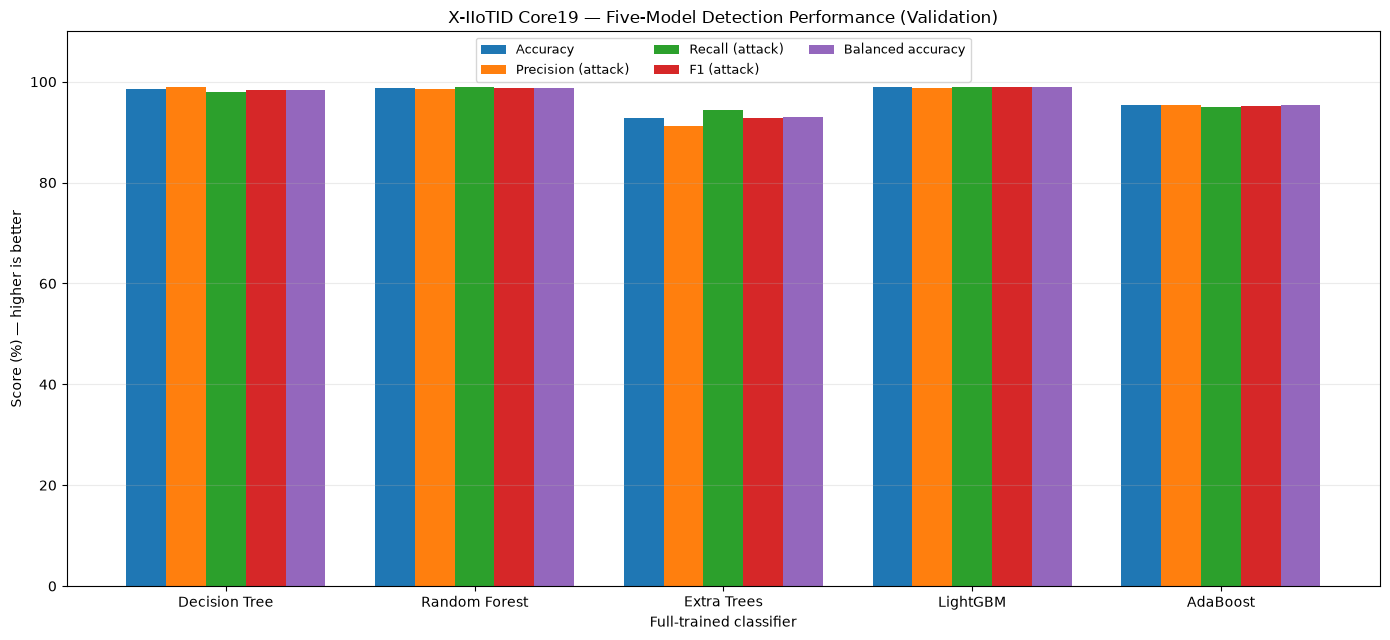

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_demo_all_detection_metrics_v2.png
Exact metric values (percent):


,Accuracy,Precision (attack),Recall (attack),F1 (attack),Balanced accuracy
model,,,,,
decision_tree,98.474,98.931,97.922,98.424,98.459
random_forest,98.778,98.487,99.010,98.748,98.785
extra_trees,92.871,91.196,94.470,92.804,92.913
lightgbm,98.947,98.798,99.042,98.920,98.950
adaboost,95.310,95.352,94.991,95.171,95.301


In [13]:
import matplotlib.pyplot as plt

order = MODELS
chart_df = performance_df.set_index("model").loc[order]
labels = [DISPLAY_NAMES[name] for name in order]
fields = ["accuracy_pct", "precision_pct", "recall_pct", "f1_pct", "balanced_accuracy_pct"]
field_labels = ["Accuracy", "Precision (attack)", "Recall (attack)", "F1 (attack)", "Balanced accuracy"]

x = np.arange(len(labels))
width = 0.16
fig, ax = plt.subplots(figsize=(14, 6.5))
for j, (field, label) in enumerate(zip(fields, field_labels)):
    positions = x + (j - (len(fields)-1)/2) * width
    bars = ax.bar(positions, chart_df[field].astype(float).values, width, label=label)
    # Numeric labels go in a short summary table below; this avoids cluttering the chart.
ax.set_title("X-IIoTID Core19 — Five-Model Detection Performance (Validation)")
ax.set_xlabel("Full-trained classifier")
ax.set_ylabel("Score (%) — higher is better")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 110)  # Honest 0-based percent scale, not cropped at 90%.
ax.legend(loc="upper center", ncol=3, fontsize=9)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
dest = FIG_DIR / "x_iiotid_demo_all_detection_metrics_v2.png"
fig.savefig(dest, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", dest)
print("Exact metric values (percent):")
display(chart_df[fields].rename(columns=dict(zip(fields, field_labels))).round(3))

## D. Graphs 2–3 — Wrong alerts and false-positive rate

- **False positive (FP):** normal flow wrongly called an attack — generates a false alert.
- **False negative (FN):** real attack wrongly called normal — a missed attack.
- **FPR:** false positives divided by **all actual normal flows**, so it is more interpretable than counts alone across datasets. The count chart is fair here because the **same 123,125-record validation partition** is used for all five models.

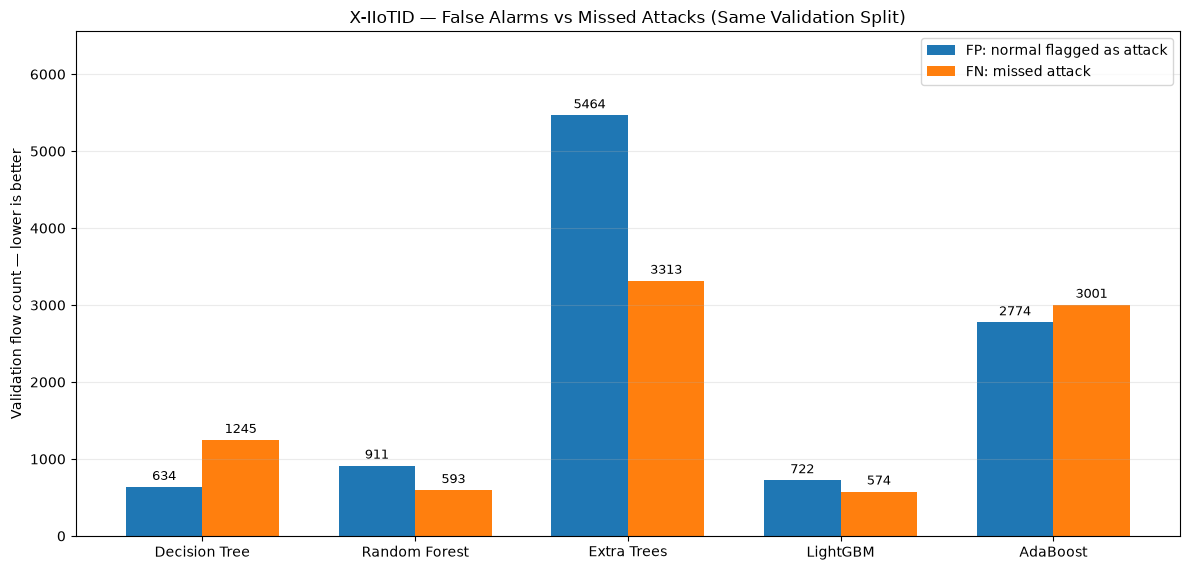

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_demo_false_alarms_missed_attacks_v2.png


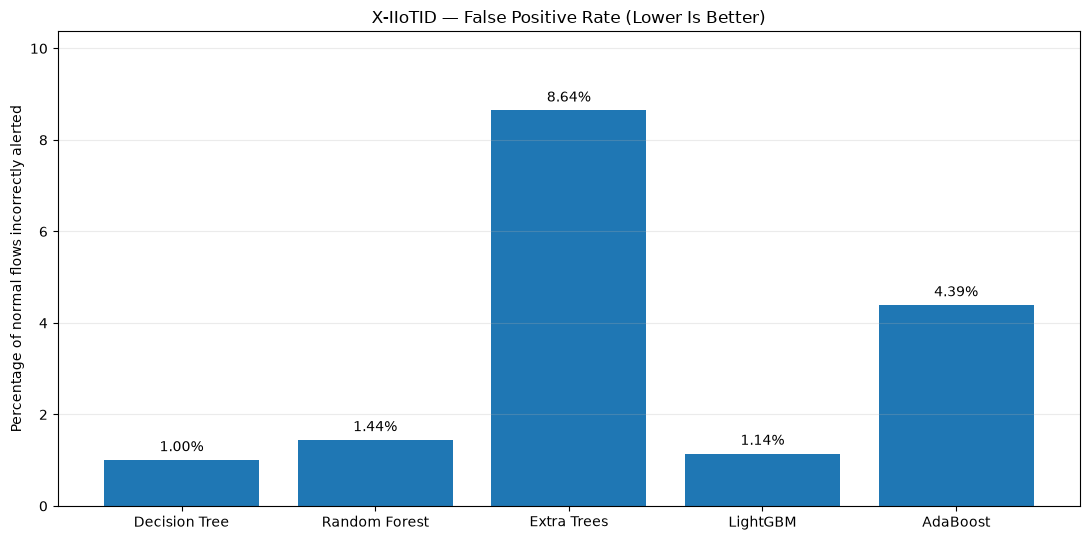

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_demo_false_positive_rate_v2.png


In [6]:
fig, ax = plt.subplots(figsize=(12, 5.8))
x = np.arange(len(labels))
width = 0.36
fp = chart_df["FP"].astype(int).values
fn = chart_df["FN"].astype(int).values
bars_fp = ax.bar(x-width/2, fp, width, label="FP: normal flagged as attack")
bars_fn = ax.bar(x+width/2, fn, width, label="FN: missed attack")
ax.bar_label(bars_fp, padding=3, fontsize=9)
ax.bar_label(bars_fn, padding=3, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylabel("Validation flow count — lower is better")
ax.set_title("X-IIoTID — False Alarms vs Missed Attacks (Same Validation Split)")
ax.set_ylim(0, max(fp.max(), fn.max())*1.2)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
dest = FIG_DIR / "x_iiotid_demo_false_alarms_missed_attacks_v2.png"
fig.savefig(dest, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", dest)

fig, ax = plt.subplots(figsize=(11, 5.5))
values = chart_df["fpr_pct"].astype(float).values
bars = ax.bar(labels, values)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=4)
ax.set_title("X-IIoTID — False Positive Rate (Lower Is Better)")
ax.set_ylabel("Percentage of normal flows incorrectly alerted")
ax.set_ylim(0, max(values)*1.2)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
dest = FIG_DIR / "x_iiotid_demo_false_positive_rate_v2.png"
fig.savefig(dest, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", dest)

## E. Fair execution method — fresh Python process per model

A separate Python process is launched for **each saved model**, so models do not share memory and influence one another. The worker imports the **exact cleaning function used in training**, samples only the validation split deterministically, checks that the model is an sklearn `Pipeline` with `preprocessing` and `classifier`, and measures the complete pipeline's `.predict()`.

- **RSS** (resident set size): actual memory occupied by the Python process. `after-load RSS − baseline RSS` is an *approximate model incremental memory cost*, not a perfect model-only allocation measure.
- **Peak RSS:** largest observed process memory during the prediction run. Sampling can miss extremely short spikes.
- **Latency:** wall time per prediction call. For single-flow requests, use **median (p50)** and **95th percentile (p95)**; for the 1,000-flow batch, compute flows/second.
- **CPU:** process CPU time relative to wall time; **100% = one fully used logical CPU**, so multi-threaded models can exceed 100%. It is **not** whole-machine CPU utilization.
- **Inputs:** 1,024 deterministically sampled *original validation rows*; `clean_features()` does numeric conversion and placeholder processing before timing, because this function is currently outside the saved pipeline. This benchmark includes **saved pipeline preprocessing** but excludes the separate `clean_features()` step, network capture and live feature computation.

**Important:** Process CPU measurements and RSS on your laptop do not substitute for a real Pi benchmark. Small timings can be noisy; repeated trials and identical hardware are needed for defensible comparisons.

In [7]:
WORKER_CODE = r'''
import sys, os, json, time, threading, gc
from pathlib import Path

root = Path(sys.argv[1]); model_name = sys.argv[2]
sys.path.insert(0, str(root / "src"))
import numpy as np
import pandas as pd
import joblib
import psutil
from sklearn.pipeline import Pipeline
from x_iiotid_model_runner import CORE19, clean_features

src = root / "data/splits/x_iiotid_core19_validation_v1.csv.gz"
model_file = root / "models/x_iiotid" / (model_name + "_core19_v1.joblib")
assert src.is_file() and model_file.is_file()

# Scan the VALIDATION partition only; obtain a deterministic spread of rows.
sampled = []
for ci, chunk in enumerate(pd.read_csv(src, dtype=str, keep_default_na=False,
                                       usecols=CORE19, chunksize=10000)):
    sampled.append(chunk.sample(n=min(128, len(chunk)), random_state=42 + ci))
raw = pd.concat(sampled, ignore_index=True).sample(n=1024, random_state=42)
X = clean_features(raw).reset_index(drop=True)
del sampled, chunk, raw
gc.collect()

proc = psutil.Process(os.getpid())
def rss(): return proc.memory_info().rss
base_rss = rss()
start_load = time.perf_counter()
model = joblib.load(model_file)  # Load only trusted, locally trained artifacts.
load_sec = time.perf_counter() - start_load
post_load_rss = rss()
if not isinstance(model, Pipeline) or not {'preprocessing','classifier'}.issubset(model.named_steps):
    raise TypeError(f"Saved {model_name} artifact is not the expected preprocessing+classifier Pipeline")

batch_sizes = (1, 32, 256, 1000)
batches = {size: X.iloc[:size].copy() for size in batch_sizes}
peak = [rss()]
stop = threading.Event()
def poll():
    while not stop.wait(0.005):
        peak[0] = max(peak[0], rss())
thread = threading.Thread(target=poll, daemon=True)
thread.start()

result = {}
try:
    for batch_size in batch_sizes:
        batch = batches[batch_size]
        for _ in range(3):
            out = model.predict(batch)
            assert len(out) == batch_size
        loops = 60 if batch_size == 1 else (25 if batch_size == 32 else 12)
        times_ms = []
        for _ in range(loops):
            t0 = time.perf_counter()
            model.predict(batch)
            times_ms.append(1000 * (time.perf_counter() - t0))
        arr = np.array(times_ms)
        result[f'batch{batch_size}_p50_ms'] = float(np.median(arr))
        result[f'batch{batch_size}_p95_ms'] = float(np.percentile(arr, 95))
        if batch_size == 1000:
            result['batch1000_throughput_flows_s'] = float(1000 / (np.mean(arr) / 1000))

    # Sustained inference CPU measurement, at least 1 second or 200 repeats.
    batch = batches[1000]
    t0 = time.perf_counter()
    c0 = proc.cpu_times()
    loops = 0
    while loops < 200 and (loops < 2 or time.perf_counter() - t0 < 1.0):
        model.predict(batch)
        loops += 1
    wall = time.perf_counter() - t0
    c1 = proc.cpu_times()
    process_cpu_seconds = (c1.user + c1.system) - (c0.user + c0.system)
    result['cpu_pct_one_logical_core'] = float(100 * process_cpu_seconds / wall)
    result['cpu_measurement_wall_seconds'] = float(wall)
    result['cpu_measurement_prediction_loops'] = loops
finally:
    peak[0] = max(peak[0], rss())
    stop.set()
    thread.join(timeout=1)

result.update({
    'model': model_name,
    'input_validation_rows_sampled': int(len(X)),
    'model_load_seconds': float(load_sec),
    'rss_baseline_mib': float(base_rss / 2**20),
    'rss_after_load_mib': float(post_load_rss / 2**20),
    'model_rss_increment_mib': float((post_load_rss - base_rss) / 2**20),
    'peak_process_rss_mib': float(peak[0] / 2**20),
    'cpu_logical_cores': os.cpu_count(),
    'python_version': sys.version.split()[0],
    'os_platform': sys.platform,
    'preprocessing_in_predict': True,
    'clean_features_timed': False,
    'network_capture_timed': False,
    'test_evaluated': False,
})
print('BENCHMARK_RESULT_JSON=' + json.dumps(result, allow_nan=False))
'''
print("Benchmark worker prepared; separate process per model.")

Benchmark worker prepared; separate process per model.


## F. Run all five saved models — **no training**

One subprocess per model using the **same active notebook kernel interpreter**. Errors are shown without hiding their full output. Expect several seconds to a minute depending on the models and laptop performance. `subprocess` is necessary for isolation; avoid running these measurements concurrently with other heavy applications.

In [8]:
import subprocess, time

# For demonstration, reuse the existing Notebook 14 *measured laptop benchmark*
# without repeating the five expensive resource tests.
REUSE_SAVED_BENCHMARK = True  # Set False to execute fresh benchmarks again
saved_benchmark_csv = AUDIT_DIR / "x_iiotid_five_model_laptop_resource_benchmark_v1.csv"
REUSED_RESOURCE_RESULTS = bool(REUSE_SAVED_BENCHMARK and saved_benchmark_csv.is_file())

if REUSED_RESOURCE_RESULTS:
    resource_df = pd.read_csv(saved_benchmark_csv)
    print("REUSED prior laptop measurements from:", saved_benchmark_csv)
    print("No CPU/RAM benchmark was rerun. Set REUSE_SAVED_BENCHMARK=False to rerun.")
else:
    print("Measuring each model in a fresh Python process (NOT training)...")
    benchmark_rows = []
    failures = {}
    for model_name in MODELS:
        print(f"Benchmarking saved {DISPLAY_NAMES[model_name]} pipeline ...", flush=True)
        started = time.perf_counter()
        try:
            completed = subprocess.run(
                [sys.executable, "-c", WORKER_CODE, str(ROOT), model_name],
                text=True, capture_output=True, timeout=240, check=True,
                cwd=str(ROOT)
            )
            output = [line.split("=", 1)[1] for line in completed.stdout.splitlines()
                      if line.startswith("BENCHMARK_RESULT_JSON=")]
            if not output:
                raise RuntimeError("Worker returned no results. stdout:\n" + completed.stdout
                                   + "\nstderr:\n" + completed.stderr)
            benchmark_rows.append(json.loads(output[-1]))
            print(f"  Success in {time.perf_counter()-started:.1f}s")
        except Exception as exc:
            message = str(exc)
            if isinstance(exc, subprocess.CalledProcessError):
                message += "\nstdout:\n" + (exc.stdout or "") + "\nstderr:\n" + (exc.stderr or "")
            failures[model_name] = message
            print(f"  FAILED: {message[:1500]}")

    if failures:
        print("\nFix benchmark errors before interpreting partial results:")
        for name, error in failures.items():
            print("\n", name, error[:3000])
        raise RuntimeError(f"{len(failures)} model(s) failed resource benchmarking")

    resource_df = metadata_df.merge(pd.DataFrame(benchmark_rows), on="model", validate="one_to_one")

assert len(resource_df) == 5 and set(resource_df["model"]) == set(MODELS)
# The selected metric CSVs are the current evidence, even if laptop measurements were reused.
resource_df["f1_attack"] = resource_df["model"].map(
    performance_df.set_index("model")["f1_pct"] / 100
)
resource_df["false_positive_rate"] = resource_df["model"].map(
    performance_df.set_index("model")["fpr_pct"] / 100
)
# Refresh file-size from the actual saved artifact on this laptop (not a new CPU benchmark).
resource_df["model_size_mib"] = resource_df["model"].map(
    {m: (MODEL_DIR / f"{m}_core19_v1.joblib").stat().st_size / 2**20 for m in MODELS}
)

view_columns = ["model", "model_size_mib", "model_load_seconds", "model_rss_increment_mib",
                "peak_process_rss_mib", "cpu_pct_one_logical_core", "batch1_p50_ms",
                "batch1_p95_ms", "batch1000_throughput_flows_s", "f1_attack"]
display(resource_df[view_columns].round(3))

REUSED prior laptop measurements from: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_five_model_laptop_resource_benchmark_v1.csv
No CPU/RAM benchmark was rerun. Set REUSE_SAVED_BENCHMARK=False to rerun.


,model,model_size_mib,model_load_seconds,model_rss_increment_mib,peak_process_rss_mib,cpu_pct_one_logical_core,batch1_p50_ms,batch1_p95_ms,batch1000_throughput_flows_s,f1_attack
0,decision_tree,0.033,0.005,0.070,198.055,100.542,8.691,11.599,80046.694,0.984
1,random_forest,2.846,0.087,6.797,206.320,117.236,38.419,41.291,19945.897,0.987
2,extra_trees,0.958,0.051,5.973,205.504,128.825,37.061,42.133,19574.675,0.928
3,lightgbm,0.215,0.057,1.379,200.426,399.295,11.466,12.978,48609.643,0.989
4,adaboost,0.029,0.043,0.090,198.105,97.338,47.750,57.040,15638.211,0.952


## G. Save the raw comparison evidence

CSV and JSON include measurement caveats. Keep full precision in files, rounding only for display. Results are **laptop measurements** of **pre-cleaned validation inputs through the saved preprocessing-and-classifier pipeline**.

In [9]:
from datetime import datetime, timezone

csv_out = AUDIT_DIR / "x_iiotid_five_model_laptop_resource_benchmark_v1.csv"
json_out = AUDIT_DIR / "x_iiotid_five_model_laptop_resource_benchmark_v1.json"
if REUSED_RESOURCE_RESULTS:
    print("Resource data REUSED from existing CSV; original measurement files left unchanged:")
    print(csv_out)
    print("The following graphs can be regenerated using the saved numbers.")
else:
    resource_df.to_csv(csv_out, index=False)
    payload = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "experiment": "Frozen X-IIoTID Core19 saved model laptop resource benchmark",
        "train_rows_reported_per_model": 574585,
        "validation_rows_available": 123125,
        "validation_rows_sampled_per_worker": 1024,
        "frozen_manifest_sha256": next(iter(manifest_hashes)),
        "hardware": "current laptop, not Raspberry Pi",
        "validation_sampling": "128 deterministic rows sampled from each 10k-row validation chunk; 1024 drawn from pooled sample",
        "model_loading": "only locally trained trusted joblib pipeline artifacts",
        "timed_prediction_includes": "fitted Pipeline.preprocessing and Pipeline.classifier",
        "timed_prediction_excludes": ["read_csv", "clean_features", "network packet capture", "flow aggregation", "dashboard/alerting"],
        "ram_definition": "process RSS; after-load increment includes allocator effects, peak RSS is sampled at 5ms intervals",
        "cpu_definition": "process CPU time / wall time; 100% is one logical CPU, >100% possible",
        "test_set_evaluated": False,
        "results": resource_df.to_dict(orient="records"),
    }
    json_out.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Saved fresh benchmark CSV:", csv_out)
    print("Saved fresh benchmark JSON:", json_out)

Resource data REUSED from existing CSV; original measurement files left unchanged:
D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_five_model_laptop_resource_benchmark_v1.csv
The following graphs can be regenerated using the saved numbers.


## H. Resource consumption: five report-ready graphs

The charts deliberately avoid arbitrary scores and benchmark only measured quantities. Resource usage is a **trade-off**: smaller storage, lower memory, lower latency and good F1 are generally desirable, but throughput and actual gateway feature availability also matter.

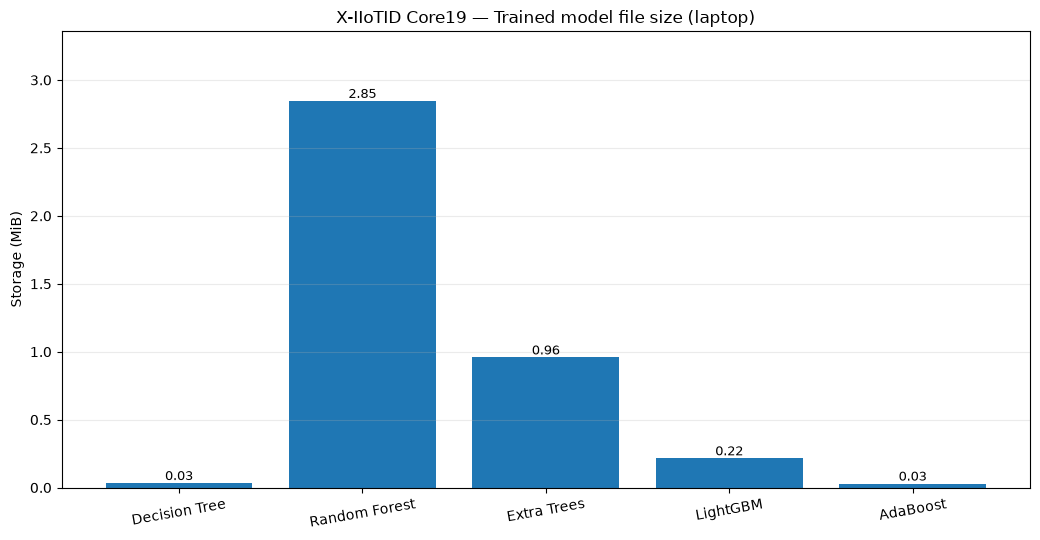

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_resource_model_file_size_v1.png


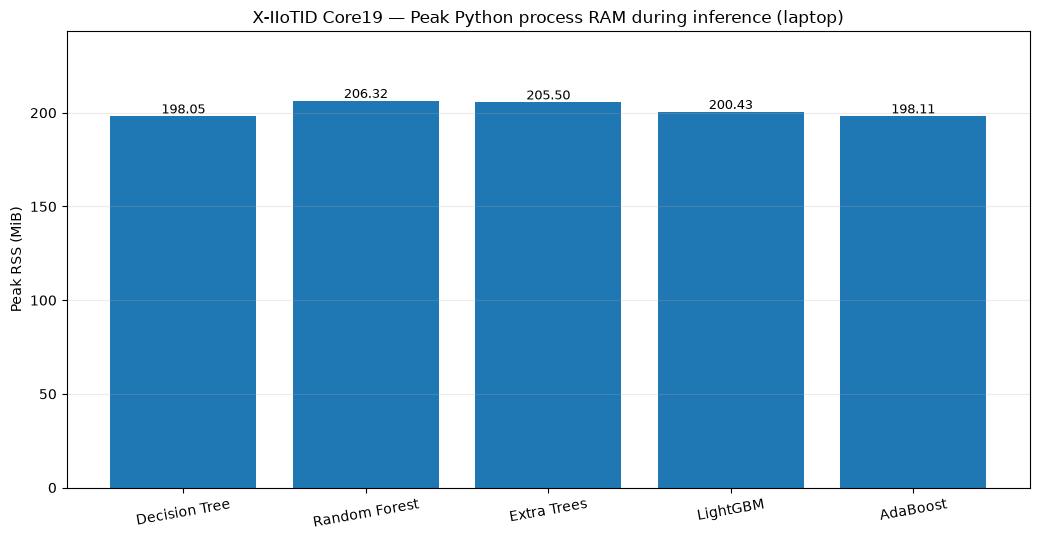

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_resource_peak_process_ram_v1.png


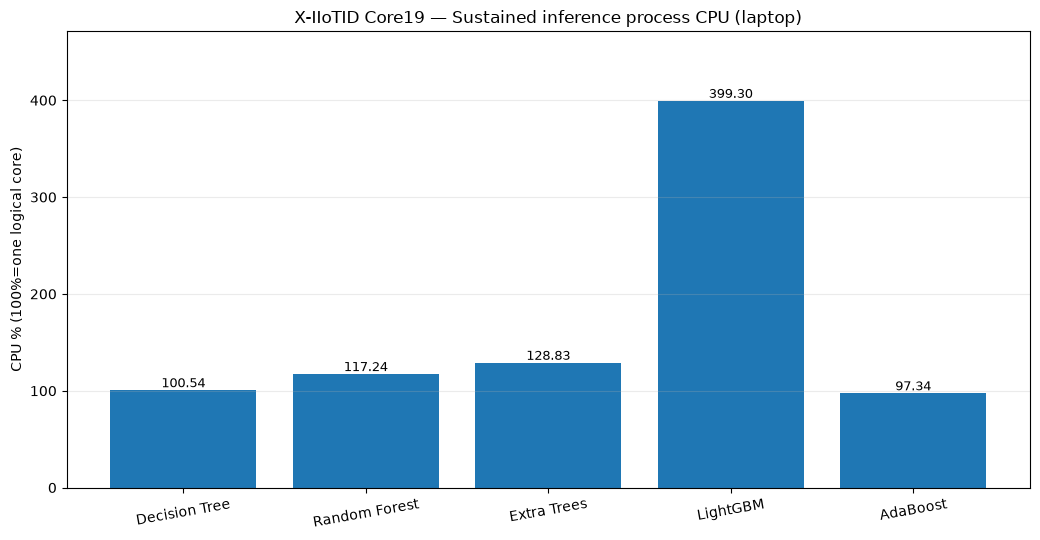

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_resource_cpu_inference_v1.png


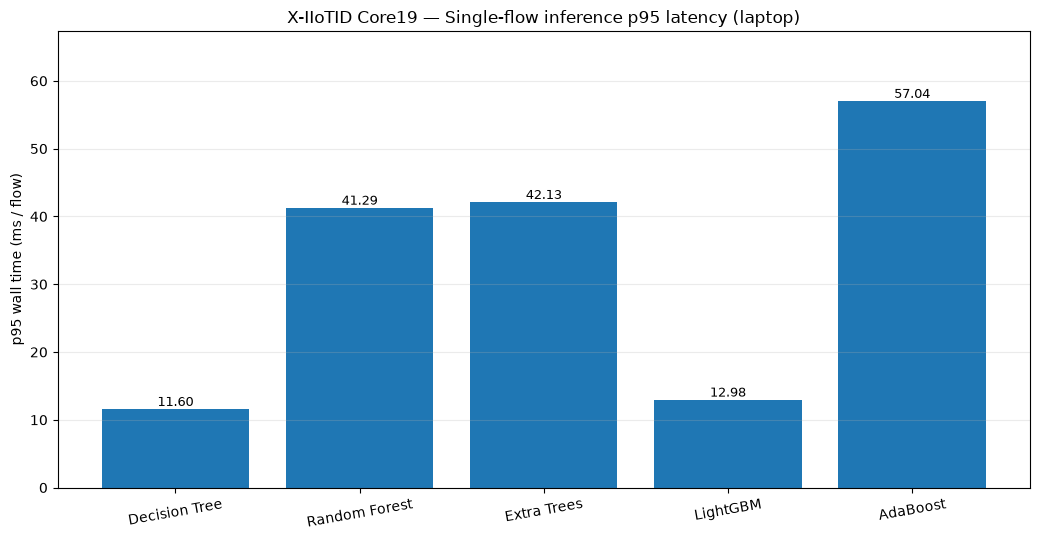

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_resource_single_flow_latency_v1.png


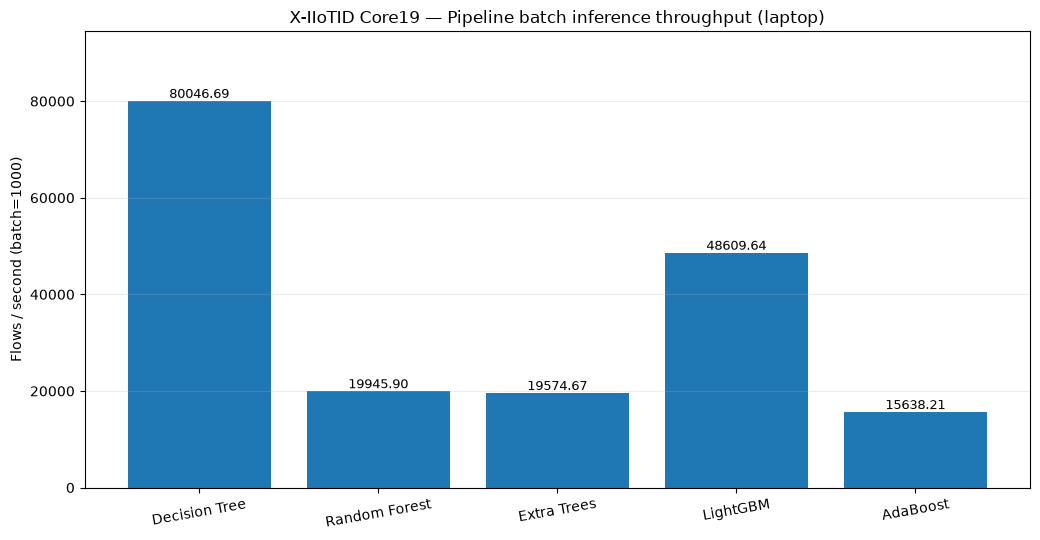

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_resource_batch_throughput_v1.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np

order = ["decision_tree", "random_forest", "extra_trees", "lightgbm", "adaboost"]
plot_df = resource_df.set_index("model").loc[order]
labels = [DISPLAY_NAMES[m] for m in order]

plots = [
    ("model_size_mib", "Trained model file size", "Storage (MiB)", "x_iiotid_resource_model_file_size_v1.png"),
    ("peak_process_rss_mib", "Peak Python process RAM during inference", "Peak RSS (MiB)", "x_iiotid_resource_peak_process_ram_v1.png"),
    ("cpu_pct_one_logical_core", "Sustained inference process CPU", "CPU % (100%=one logical core)", "x_iiotid_resource_cpu_inference_v1.png"),
    ("batch1_p95_ms", "Single-flow inference p95 latency", "p95 wall time (ms / flow)", "x_iiotid_resource_single_flow_latency_v1.png"),
    ("batch1000_throughput_flows_s", "Pipeline batch inference throughput", "Flows / second (batch=1000)", "x_iiotid_resource_batch_throughput_v1.png"),
]

for field, title, ylabel, filename in plots:
    fig, ax = plt.subplots(figsize=(10.5, 5.5))
    values = plot_df[field].astype(float).values
    bars = ax.bar(labels, values)
    ax.set_title("X-IIoTID Core19 — " + title + " (laptop)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.18 if max(values) > 0 else 1)
    ax.grid(axis="y", alpha=0.25)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    plt.xticks(rotation=10)
    fig.tight_layout()
    destination = FIG_DIR / filename
    fig.savefig(destination, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", destination)

## I. Combine detection and resource evidence — model shortlist chart

- **Top-left is preferable:** higher attack F1 and lower single-flow p95 latency on the laptop.
- **Exploratory screening rule:** F1 ≥ 98% **and** FPR ≤ 2%. This is a provisional experiment threshold, *not* a Raspberry Pi hardware requirement.
- The shortlist is **not** proof that a voting/stacking ensemble will help. Later test **complementary prediction errors**, full combined memory/CPU/latency, deployment feature feasibility, and live Pi benchmarks.
- A lower model size does not mean equivalently lower **process RSS**. LightGBM's high laptop process CPU figure needs **thread-controlled tests** before claiming edge efficiency.

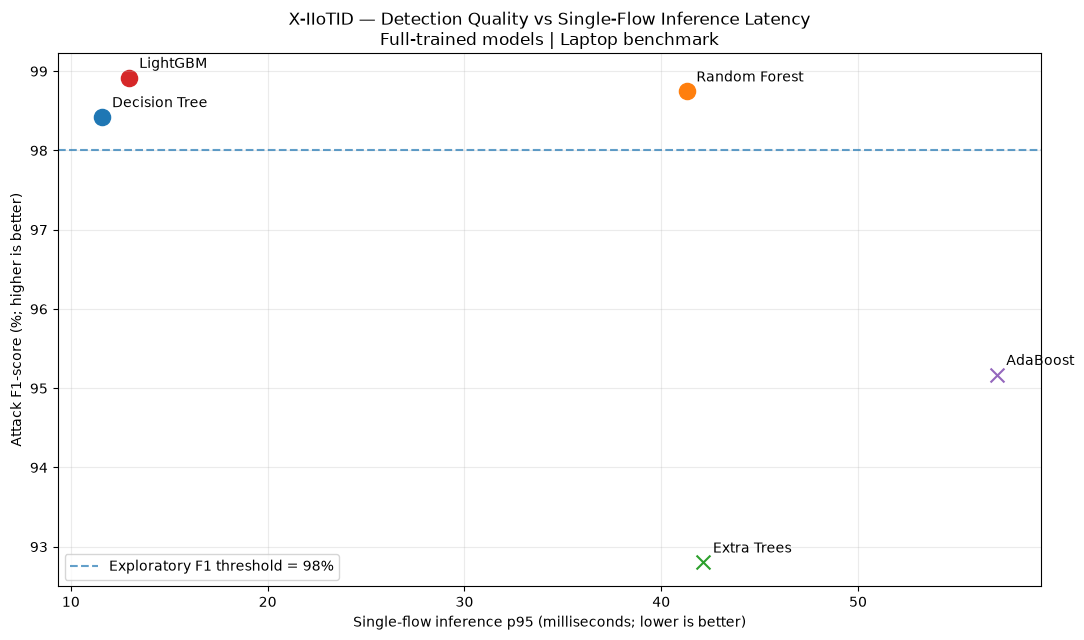

,model,f1_pct,precision_pct,recall_pct,fpr_pct,FP,FN,model_size_mib,peak_process_rss_mib,cpu_pct_one_logical_core,batch1_p95_ms,batch1000_throughput_flows_s,screening_status
3,lightgbm,98.920,98.798,99.042,1.142,722,574,0.215,200.426,399.295,12.978,48609.643,PROVISIONAL CANDIDATE
1,random_forest,98.748,98.487,99.010,1.441,911,593,2.846,206.320,117.236,41.291,19945.897,PROVISIONAL CANDIDATE
0,decision_tree,98.424,98.931,97.922,1.003,634,1245,0.033,198.055,100.542,11.599,80046.694,PROVISIONAL CANDIDATE
4,adaboost,95.171,95.352,94.991,4.388,2774,3001,0.029,198.105,97.338,57.040,15638.211,REFERENCE BASELINE
2,extra_trees,92.804,91.196,94.470,8.644,5464,3313,0.958,205.504,128.825,42.133,19574.675,REFERENCE BASELINE


Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\x_iiotid_demo_model_selection_tradeoff_v2.png
Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\x_iiotid_demo_model_selection_evidence_v2.csv

DEMO-READY REASONS (directly supported by these results)
Best F1: LightGBM
Lowest FPR: Decision Tree
Fastest p95 single flow: Decision Tree
Highest 1000-flow batch throughput: Decision Tree
Provisional shortlist: Decision Tree, Random Forest, LightGBM
Resource measurements are LAPTOP-ONLY. Shortlisting does not prove an ensemble improves accuracy or resource use.


In [11]:
# Join recomputed detection metrics to the *measured* resource results.
evidence = performance_df.merge(
    resource_df[["model", "model_size_mib", "peak_process_rss_mib",
                 "cpu_pct_one_logical_core", "batch1_p95_ms",
                 "batch1000_throughput_flows_s"]],
    on="model", validate="one_to_one"
)
MIN_F1_PCT = 98.0  # exploratory researcher-defined screening requirement
MAX_FPR_PCT = 2.0

evidence["passes_initial_screen"] = (
    (evidence["f1_pct"] >= MIN_F1_PCT) & (evidence["fpr_pct"] <= MAX_FPR_PCT)
)
evidence["screening_status"] = np.where(
    evidence["passes_initial_screen"], "PROVISIONAL CANDIDATE", "REFERENCE BASELINE"
)

evidence = evidence.set_index("model").loc[MODELS].reset_index()
fig, ax = plt.subplots(figsize=(11, 6.5))
for _, row in evidence.iterrows():
    ax.scatter(row["batch1_p95_ms"], row["f1_pct"],
               s=135 if row["passes_initial_screen"] else 100,
               marker="o" if row["passes_initial_screen"] else "x")
    ax.annotate(DISPLAY_NAMES[row["model"]],
                (row["batch1_p95_ms"], row["f1_pct"]),
                xytext=(7, 7), textcoords="offset points", fontsize=10)
ax.axhline(MIN_F1_PCT, linestyle="--", alpha=0.7,
           label=f"Exploratory F1 threshold = {MIN_F1_PCT:.0f}%")
ax.set_title("X-IIoTID — Detection Quality vs Single-Flow Inference Latency\nFull-trained models | Laptop benchmark")
ax.set_xlabel("Single-flow inference p95 (milliseconds; lower is better)")
ax.set_ylabel("Attack F1-score (%; higher is better)")
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
select_png = FIG_DIR / "x_iiotid_demo_model_selection_tradeoff_v2.png"
fig.savefig(select_png, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

cols = ["model", "f1_pct", "precision_pct", "recall_pct", "fpr_pct", "FP", "FN",
        "model_size_mib", "peak_process_rss_mib", "cpu_pct_one_logical_core",
        "batch1_p95_ms", "batch1000_throughput_flows_s", "screening_status"]
selected = evidence[cols].sort_values("f1_pct", ascending=False)
display(selected.round(3))
select_csv = AUDIT_DIR / "x_iiotid_demo_model_selection_evidence_v2.csv"
selected.to_csv(select_csv, index=False)
print("Saved:", select_png)
print("Saved:", select_csv)

print("\nDEMO-READY REASONS (directly supported by these results)")
print("Best F1:", DISPLAY_NAMES[evidence.loc[evidence["f1_pct"].idxmax(), "model"]])
print("Lowest FPR:", DISPLAY_NAMES[evidence.loc[evidence["fpr_pct"].idxmin(), "model"]])
print("Fastest p95 single flow:", DISPLAY_NAMES[evidence.loc[evidence["batch1_p95_ms"].idxmin(), "model"]])
print("Highest 1000-flow batch throughput:", DISPLAY_NAMES[evidence.loc[evidence["batch1000_throughput_flows_s"].idxmax(), "model"]])
print("Provisional shortlist:", ", ".join(DISPLAY_NAMES[m] for m in evidence.loc[evidence["passes_initial_screen"], "model"]))
print("Resource measurements are LAPTOP-ONLY. Shortlisting does not prove an ensemble improves accuracy or resource use.")

## K. Interpret results for the Raspberry Pi deployment decision

1. **F1-score** indicates detection quality on a provisional **signature-disjoint** validation split; it is **not** independently confirmed real-world APT detection.
2. **Model file size** is storage on disk. It is not equal to peak RAM usage.
3. **Peak RSS** includes the Python interpreter, dependencies, sampled feature DataFrame and loaded model. Use this for sizing the full Pi detection service, rather than only model incremental RSS.
4. **Latency** here is per prepared flow's `Pipeline.predict()`, **excluding** packet capture, flow duration, window collection and `clean_features()` outside the saved pipeline. This is not end-to-end alert latency.
5. **CPU percentage** uses process time normalized to one logical CPU; a four-core Pi can have up to ~400% aggregate usage under this convention.
6. **Pi compatibility:** Train on the laptop; copy only the trusted `.joblib` model and matching dependency versions to the Pi. Since sklearn/lightgbm serialization is version-sensitive, verify the same package versions or re-export safely if needed.
7. **Final hardware evidence:** Repeat with Raspberry Pi 4/5 and its actual network gateway load and feature extractor; measure continuous monitoring, alert path, power/temperature/throttling and throughput under realistic traffic.

**Research caution:** `Service`, `Duration`, byte counts and placeholder patterns can create dataset-specific shortcuts. A high F1 or fast inference does not replace feature-semantic and dataset-generalization checks.

In [12]:
# Easy-to-read deployment shortlist: order by validation F1 (quality), with resource costs alongside.
summary_cols = ["model", "f1_attack", "false_positive_rate", "model_size_mib",
                "peak_process_rss_mib", "batch1_p95_ms", "batch1000_throughput_flows_s",
                "cpu_pct_one_logical_core"]
shortlist = resource_df[summary_cols].sort_values("f1_attack", ascending=False).reset_index(drop=True)
display(shortlist.round(3))
print("Interpret jointly: F1 + false-positive rate + RAM + latency + gateway-extractable features.")
print("NO Raspberry Pi measurements were performed in this notebook.")

,model,f1_attack,false_positive_rate,model_size_mib,peak_process_rss_mib,batch1_p95_ms,batch1000_throughput_flows_s,cpu_pct_one_logical_core
0,lightgbm,0.989,0.011,0.215,200.426,12.978,48609.643,399.295
1,random_forest,0.987,0.014,2.846,206.320,41.291,19945.897,117.236
2,decision_tree,0.984,0.010,0.033,198.055,11.599,80046.694,100.542
3,adaboost,0.952,0.044,0.029,198.105,57.040,15638.211,97.338
4,extra_trees,0.928,0.086,0.958,205.504,42.133,19574.675,128.825


Interpret jointly: F1 + false-positive rate + RAM + latency + gateway-extractable features.
NO Raspberry Pi measurements were performed in this notebook.
